# Project 01: Exploratory Data Analysis (EDA) on Titanic
**InternCircle | Data Science & AI**

**Objective:** Load, inspect, clean, and analyse the Titanic passenger dataset with Pandas. Use grouping and aggregation to investigate survival patterns by sex, passenger class, and age group.

## Research questions
1. Did women survive at a higher rate than men?
2. Did passenger class affect the survival rate?
3. How did survival rates differ across age groups?

> This notebook follows the supplied Project 01 learner guide. The analysis describes associations in this dataset; it does not prove that any factor caused survival.

## 1. Import libraries and load the dataset

The learner guide recommends Python 3.10+, Jupyter, Pandas, NumPy, Matplotlib, Seaborn, and `sns.load_dataset("titanic")`.

If the online Seaborn dataset cannot be downloaded, place a Titanic CSV named `titanic.csv` in the same folder as this notebook. The fallback expects the usual Titanic column names (such as `survived`, `sex`, `age`, `pclass`, and `embarked`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = sns.load_dataset("titanic")
    print("Dataset loaded using Seaborn.")
except Exception:
    df = pd.read_csv("titanic.csv")
    print("Dataset loaded from local titanic.csv.")

print("Dataset loaded successfully.")

Dataset loaded using Seaborn.
Dataset loaded successfully.


## 2. Understand the dataset

- `shape` reports the number of rows and columns.
- `head()` previews the first five records.
- `info()` shows column names, data types, and non-null counts.
- `describe()` provides descriptive statistics for numeric columns.

The dataset's rows represent passengers; columns contain passenger characteristics and the survival outcome.

In [2]:
print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Check missing values

Use `isna().sum()` to count missing values in each column. The learner guide notes that `age` and `deck` have many missing values in the Seaborn Titanic dataset.

In [3]:
missing_before = df.isna().sum().sort_values(ascending=False)
missing_before = missing_before[missing_before > 0]
display(missing_before.to_frame("missing_count"))

missing_percent = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(missing_percent[missing_percent > 0].to_frame("missing_percent"))

,missing_count
deck,688
age,177
embarked,2
embark_town,2


,missing_percent
deck,77.22
age,19.87
embarked,0.22
embark_town,0.22


## 4. Clean missing values with reasons

Cleaning decisions:
- **Age:** Fill missing values with the median age for the same passenger class (`pclass`) and sex. Median is less affected by extreme values than the mean, and grouping by class and sex keeps the imputation more specific.
- **Deck:** Drop this column because the guide identifies it as mostly empty. Retaining a column with extensive missingness may add little value to this beginner analysis.
- **Embarked:** Fill missing values with the mode (most common category), as required by the guide.
- **Other columns:** Do not remove rows blindly. Keep other missing values unless they are needed for a particular calculation.

In [4]:
# Work on a copy so the original data remains available for reference.
df_clean = df.copy()

# Fill age by the median within each passenger class and sex.
df_clean["age"] = df_clean["age"].fillna(
    df_clean.groupby(["pclass", "sex"])["age"].transform("median")
)

# Drop deck because it is mostly empty in this dataset.
if "deck" in df_clean.columns:
    df_clean = df_clean.drop(columns=["deck"])

# Fill embarked with its most frequent category.
if "embarked" in df_clean.columns and df_clean["embarked"].isna().any():
    df_clean["embarked"] = df_clean["embarked"].fillna(
        df_clean["embarked"].mode()[0]
    )

print("Missing values after cleaning:")
display(df_clean.isna().sum().to_frame("missing_count"))

Missing values after cleaning:


,missing_count
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


## 5. Check duplicate rows and data types

`duplicated().sum()` counts exact duplicate rows. Inspect the data types to confirm that numeric fields remain numeric and category-like fields are stored appropriately. Do not automatically delete duplicates without checking whether they are genuine repeated records.

In [5]:
print("Duplicate rows:", df_clean.duplicated().sum())
display(df_clean.dtypes.to_frame("data_type"))

# Convert common category columns to category dtype when present.
for col in ["sex", "embarked", "class", "who", "adult_male", "alone"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype("category")

# Ensure key numeric analysis columns are numeric.
for col in ["survived", "pclass", "age", "fare"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

display(df_clean.dtypes.to_frame("cleaned_data_type"))

Duplicate rows: 118


,data_type
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,category
who,object


,cleaned_data_type
survived,int64
pclass,int64
sex,category
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,category
class,category
who,category


## 6. Group and compare survival rates

The `survived` column uses 1 for survived and 0 for did not survive. Therefore, the mean of this column within a group is that group's survival proportion. Multiply by 100 to express it as a percentage.

In [6]:
# Survival rate by sex
survival_by_sex = (
    df_clean.groupby("sex", observed=True)["survived"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "survival_rate", "count": "passenger_count"})
)
survival_by_sex["survival_percent"] = (survival_by_sex["survival_rate"] * 100).round(2)
display(survival_by_sex.sort_values("survival_rate", ascending=False))

# Survival rate by passenger class
survival_by_class = (
    df_clean.groupby("pclass", observed=True)["survived"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "survival_rate", "count": "passenger_count"})
)
survival_by_class["survival_percent"] = (survival_by_class["survival_rate"] * 100).round(2)
display(survival_by_class.sort_values("survival_rate", ascending=False))

,survival_rate,passenger_count,survival_percent
sex,,,
female,0.742038,314,74.20
male,0.188908,577,18.89


,survival_rate,passenger_count,survival_percent
pclass,,,
1,0.629630,216,62.96
2,0.472826,184,47.28
3,0.242363,491,24.24


In [7]:
# Create age bands as specified in the learner guide.
age_bins = [0, 12, 18, 40, 60, 100]
age_labels = ["Child", "Teen", "Adult", "Middle-aged", "Senior"]

df_clean["age_band"] = pd.cut(
    df_clean["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

survival_by_age = (
    df_clean.groupby("age_band", observed=True)["survived"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "survival_rate", "count": "passenger_count"})
)
survival_by_age["survival_percent"] = (survival_by_age["survival_rate"] * 100).round(2)
display(survival_by_age)

,survival_rate,passenger_count,survival_percent
age_band,,,
Child,0.579710,69,57.97
Teen,0.428571,70,42.86
Adult,0.360465,602,36.05
Middle-aged,0.390625,128,39.06
Senior,0.227273,22,22.73


## 7. Visualise the comparisons

The charts provide a visual comparison of the survival percentages. The tables above remain the source for the exact numerical values.

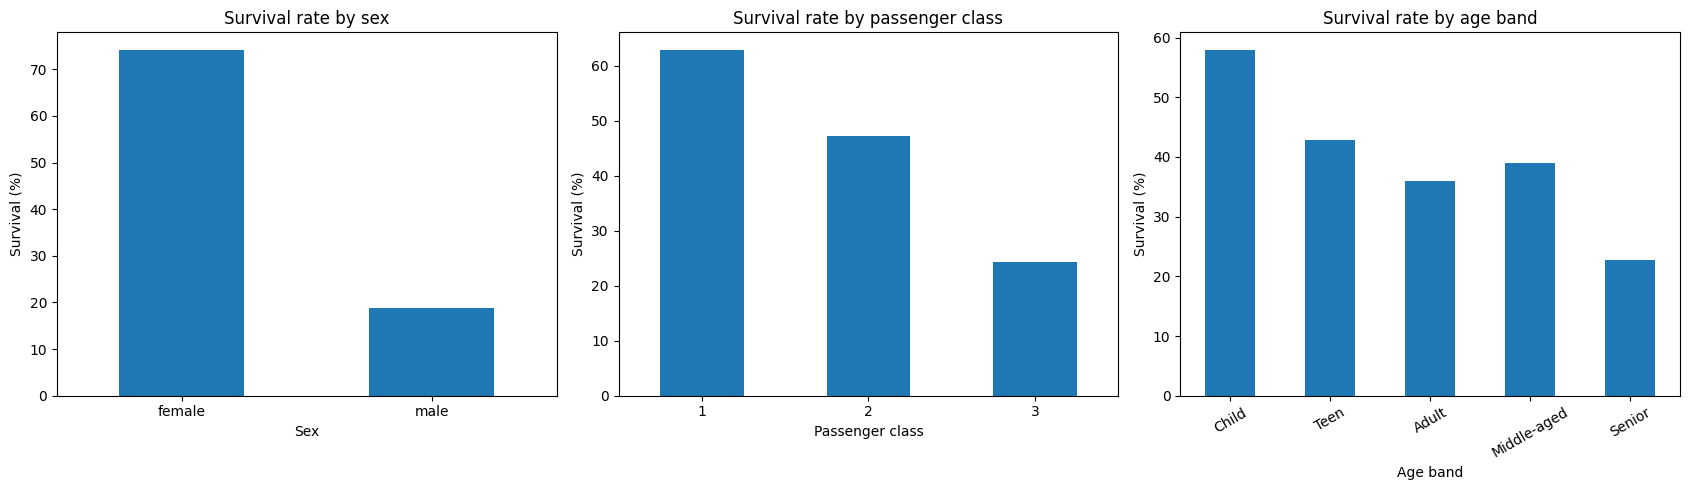

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

(survival_by_sex["survival_percent"]
 .sort_values(ascending=False)
 .plot(kind="bar", ax=axes[0], title="Survival rate by sex", ylabel="Survival (%)"))
axes[0].set_xlabel("Sex")
axes[0].tick_params(axis="x", rotation=0)

(survival_by_class["survival_percent"]
 .sort_index()
 .plot(kind="bar", ax=axes[1], title="Survival rate by passenger class", ylabel="Survival (%)"))
axes[1].set_xlabel("Passenger class")
axes[1].tick_params(axis="x", rotation=0)

(survival_by_age["survival_percent"]
 .plot(kind="bar", ax=axes[2], title="Survival rate by age band", ylabel="Survival (%)"))
axes[2].set_xlabel("Age band")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 8. Answer the three research questions

The following cell creates three evidence-based sentences directly from the calculated results. Run it after the analysis cells and use the generated sentences in your final project summary.

In [9]:
def best_and_worst(table, label_col):
    ordered = table.sort_values("survival_rate", ascending=False)
    best_label = ordered.index[0]
    best_rate = ordered.iloc[0]["survival_percent"]
    worst_label = ordered.index[-1]
    worst_rate = ordered.iloc[-1]["survival_percent"]
    return best_label, best_rate, worst_label, worst_rate

best_sex, best_sex_rate, low_sex, low_sex_rate = best_and_worst(survival_by_sex, "sex")
best_class, best_class_rate, low_class, low_class_rate = best_and_worst(survival_by_class, "pclass")
best_age, best_age_rate, low_age, low_age_rate = best_and_worst(survival_by_age, "age_band")

print(
    f"Q1. Survival differed by sex: the {best_sex} group had the highest observed "
    f"survival rate ({best_sex_rate:.2f}%), compared with {low_sex} "
    f"({low_sex_rate:.2f}%)."
)
print(
    f"Q2. Passenger class showed a difference: class {best_class} had the highest "
    f"observed survival rate ({best_class_rate:.2f}%), while class {low_class} "
    f"had {low_class_rate:.2f}%."
)
print(
    f"Q3. Across age bands, {best_age} had the highest observed survival rate "
    f"({best_age_rate:.2f}%), while {low_age} had {low_age_rate:.2f}%."
)

Q1. Survival differed by sex: the female group had the highest observed survival rate (74.20%), compared with male (18.89%).
Q2. Passenger class showed a difference: class 1 had the highest observed survival rate (62.96%), while class 3 had 24.24%.
Q3. Across age bands, Child had the highest observed survival rate (57.97%), while Senior had 22.73%.


## 9. Conclusion

This exploratory analysis inspected the Titanic dataset, measured missing values, cleaned selected columns using documented reasons, checked duplicates and data types, and compared survival rates by sex, passenger class, and age band.

Use the three numerical sentences printed in Section 8 as the findings in your submission. The results show patterns in this dataset only. They should not be interpreted as proof of causation.

## 10. Final submission checklist

- [ ] Three research questions are written at the beginning.
- [ ] Dataset inspection includes `shape`, `head()`, `info()`, and `describe()`.
- [ ] Missing values are counted and cleaning decisions are explained.
- [ ] Duplicate rows and data types are checked.
- [ ] Survival is compared by at least three factors: sex, class, and age band.
- [ ] Each research question has a one-sentence answer containing a numerical result.
- [ ] Restart the kernel and run all cells from top to bottom without errors.
- [ ] Export the completed notebook to HTML or PDF.
- [ ] Share the notebook link or exported HTML, plus the short three-finding summary.

**Submission items required by the guide:** a viewable notebook link (GitHub/Colab) or exported HTML file, and a short written summary of the three findings.